# CSI transport replay: EDA, preprocessing, and CNN training

This executed notebook examines recorded **100 Hz, two-receiver CSI** under hypothetical lower-rate sensing, upload scheduling, packet loss, and constrained BLE delivery. The original recordings remain immutable.

Four-slot simulations add **two virtual byte workloads**, not additional CSI views. Every throughput, burst, and retry parameter is an assumption. This experiment evaluates a two-view classifier under those assumptions; it does not measure BLE hardware.

The fixed cohort and scenario split come from the earlier CNN pilot. That test set has already been inspected, so this is an **exploratory within-session comparison**, not a fresh independent evaluation. Run All reads saved outputs. The final optional cell can rerun the full experiment into separate directories.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
if ROOT.name != "04_transport_simulation":
    ROOT = ROOT / "notebooks" / "04_transport_simulation"
RESULTS = ROOT / "results" / "replay_v1"
CONFIG = json.loads((ROOT / "config.json").read_text())
manifest = json.loads((RESULTS / "manifest.json").read_text())
trials = pd.read_csv(RESULTS / "trials.csv")
pd.set_option("display.max_columns", 16)
print(f"{len(trials)} original attempts; receivers: {CONFIG['receivers']}")
print(manifest["scope"])

154 original attempts; receivers: ['rx-1', 'rx-2']
Two real CSI views; four-slot cases add two virtual traffic sources only. Reused within-session pilot split; prior test set already inspected. All transport/loss parameters are assumptions.


## 1. Experimental conditions and frozen cohort

`original_100` is the source baseline with ideal replacement transport. Rate thinning preserves the observed timestamps: four of every five 100 Hz rounds approximate 80 Hz with **10/20 ms spacing**, rather than manufacturing uniform 12.5 ms samples.

Round-robin/random grants make the owner blind for that retained sensing round. Four-slot cases give each measured view 25% nominal scheduling exposure, while virtual receivers contribute competing traffic only. Natural source losses are preserved. Synthetic losses are imposed on the remaining observed opportunities.

No attempt is removed because simulated loss makes it difficult. All variants stay in the original scenario partition; repetitions and both receiver views remain together.

In [2]:
display(pd.DataFrame(CONFIG["conditions"]).fillna("—"))
display(pd.crosstab(trials.label, trials.split))
assert trials.groupby("scenario_id").split.nunique().max() == 1
assert set(CONFIG["training_realizations"]).isdisjoint(
    [CONFIG["validation_realization"], CONFIG["test_realization"]]
)

,name,rate_hz,scheduler,slots,independent_loss,burst_enter,burst_exit,service_bps,transfer_failure,maximum_retries
0,original_100,100,none,2,—,—,—,—,—,—
1,rate_80,80,none,2,—,—,—,—,—,—
2,rr2_80,80,round_robin,2,—,—,—,—,—,—
3,rr4_80,80,round_robin,4,—,—,—,—,—,—
4,random4_80,80,random,4,—,—,—,—,—,—
5,loss4_80,80,round_robin,4,0.05,0.015,0.25,—,—,—
6,ble4_1400k,80,round_robin,4,0.05,0.015,0.25,1400000.0,0.03,1.0
7,ble4_1000k,80,round_robin,4,0.05,0.015,0.25,1000000.0,0.03,1.0


split,test,train,validation
label,,,
sit_to_fall,4,10,4
sit_to_stand,2,4,2
sit_to_walk,6,20,6
stand_to_fall,6,20,6
walk_to_fall,6,20,6
walk_to_sit,6,20,6


## 2. Packet EDA on training attempts

The EDA below uses training attempts and replay realization 101. Timely records meet each capture bin's finalization deadline (bin end + 100 ms). Packet-level longest gaps include unsupported intervals at window edges. A high average rate does not establish short gaps or useful spatial coverage.

,condition,receiver,attempts,median_timely_hz,p10_timely_hz,p90_longest_gap_s,median_p95_delay_s,median_peak_queue
0,ble4_1000k,rx-1,94,0.00,0.00,4.0000,0.2387,16.0
1,ble4_1000k,rx-2,94,0.00,0.00,4.0000,0.2412,16.0
2,ble4_1400k,rx-1,94,54.00,51.25,0.1900,0.0638,5.0
3,ble4_1400k,rx-2,94,54.00,51.50,0.1800,0.0625,5.0
4,loss4_80,rx-1,94,54.00,51.25,0.1900,0.0000,0.0
5,loss4_80,rx-2,94,54.00,51.50,0.1800,0.0000,0.0
6,original_100,rx-1,94,100.00,100.00,0.0100,0.0000,0.0
7,original_100,rx-2,94,100.00,100.00,0.0101,0.0000,0.0
8,random4_80,rx-1,94,60.25,57.75,0.0770,0.0000,0.0
9,random4_80,rx-2,94,60.00,57.75,0.0800,0.0000,0.0


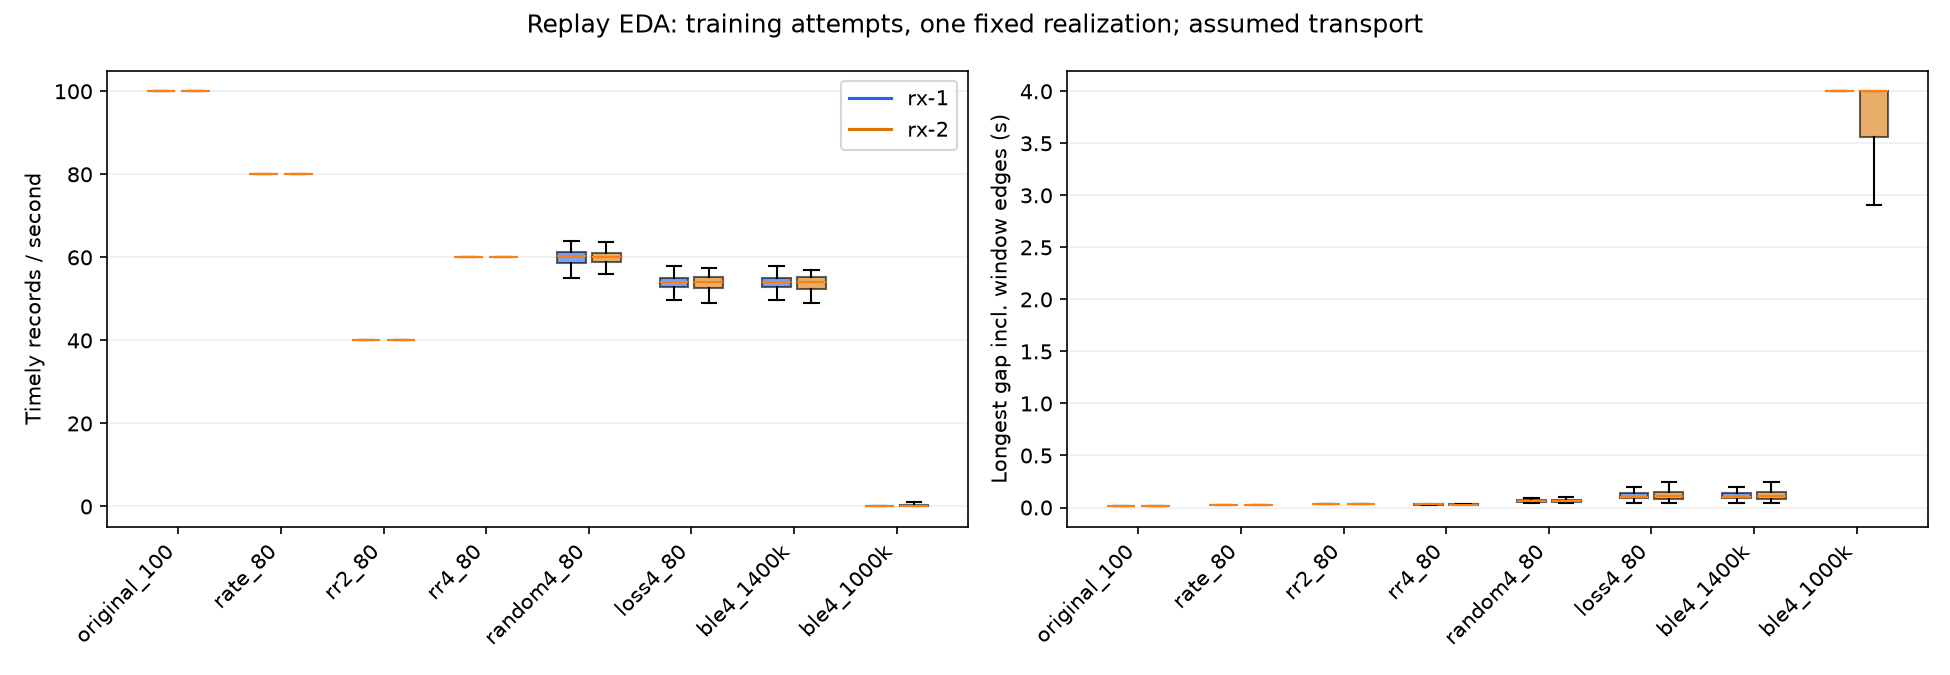

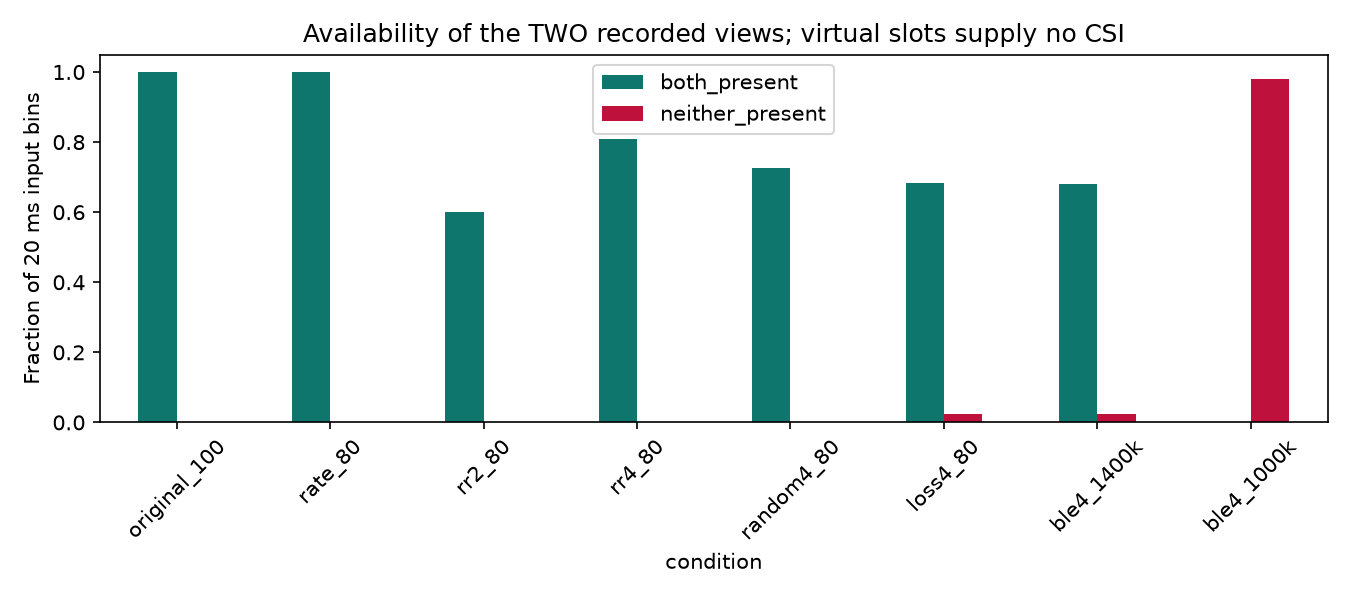

In [3]:
eda = pd.read_csv(RESULTS / "eda_training_summary.csv")
display(eda.round(4))
display(Image(filename=str(RESULTS / "figures" / "packet_coverage.png")))
display(Image(filename=str(RESULTS / "figures" / "joint_coverage.png")))

## 3. Queue and delivery replay

Captured packets enter bounded queues. A separate uniform target-rate clock supplies equal-length upload grants, assumed announced ahead of time, after a 1 ms guard. The original capture timestamps retain thinning jitter. Only the upload owner gets service in its grant. Partial records can continue in that receiver's later grants. Records expire after 250 ms; overflow evicts the oldest record. Capacity is shared, unused service does not accumulate, and retries consume service.

The constrained cases use assumed 1.4/1.0 Mbit/s application service, record/batch metadata and per-fragment headers. Whole-transfer failures stand in for unsuccessful delivery, with one bounded retry. This abstract service model does **not** reproduce BLE connection anchors, maintenance events, ACK latency, or RF coexistence. Hardware traces will be needed to calibrate it.

An unavailable capture never enters the queue. A captured but late packet remains absent from its original finalized input bin. If it later arrives, it can update subsequent age metadata without filling another capture bin.

Replay includes countdown before the four-second action window, so queue state is warmed up rather than reset at the cue. This matters for sustained overload.


reason                 delivered  expired  pending  radio_burst  \
condition    receiver                                             
ble4_1000k   rx-1            167       36        8           29   
             rx-2            160       60        8           13   
ble4_1400k   rx-1            211        0        0           29   
             rx-2            227        0        0           13   
loss4_80     rx-1            211        0        0           29   
             rx-2            228        0        0           13   
original_100 rx-1            420        0        0            0   
             rx-2            420        0        0            0   
random4_80   rx-1            258        0        0            0   
             rx-2            250        0        0            0   
rate_80      rx-1            336        0        0            0   
             rx-2            336        0        0            0   
rr2_80       rx-1            168        0        0            0   
             rx-2            168        0        0            0   
rr4_80       rx-1            252        0        0            0   
             rx-2            252        0        0            0   

reason                 radio_independent  rate_removed  retry_limit  scheduled  
condition    receiver                                                           
ble4_1000k   rx-1                     12            84            0         84  
             rx-2                     11            84            0         84  
ble4_1400k   rx-1                     12            84            0         84  
             rx-2                     11            84            1         84  
loss4_80     rx-1                     12            84            0         84  
             rx-2                     11            84            0         84  
original_100 rx-1                      0             0            0          0  
             rx-2                      0             0            0          0  
random4_80   rx-1                      0            84            0         78  
             rx-2                      0            84            0         86  
rate_80      rx-1                      0            84            0          0  
             rx-2                      0            84            0          0  
rr2_80       rx-1                      0            84            0        168  
             rx-2                      0            84            0        168  
rr4_80       rx-1                      0            84            0         84  
             rx-2                      0            84            0         84

,condition,receiver,sequence,capture_s,arrival_s,reason
5880,ble4_1000k,rx-1,319706,-0.195857,NaN,rate_removed
5881,ble4_1000k,rx-1,319707,-0.185856,0.042954,delivered
5882,ble4_1000k,rx-1,319708,-0.175856,NaN,expired
5883,ble4_1000k,rx-1,319709,-0.165856,NaN,scheduled
5884,ble4_1000k,rx-1,319710,-0.155856,0.087794,delivered
5885,ble4_1000k,rx-1,319711,-0.145856,NaN,rate_removed
5886,ble4_1000k,rx-1,319712,-0.135855,0.092954,delivered
5887,ble4_1000k,rx-1,319713,-0.125856,NaN,expired
5888,ble4_1000k,rx-1,319714,-0.115856,NaN,scheduled
5889,ble4_1000k,rx-1,319715,-0.105856,0.137794,delivered


,attempts,median_clock_uncertainty_us,maximum_clock_uncertainty_us
receiver,,,
rx-1,154,70.187574,193.604174
rx-2,154,74.068765,228.210647


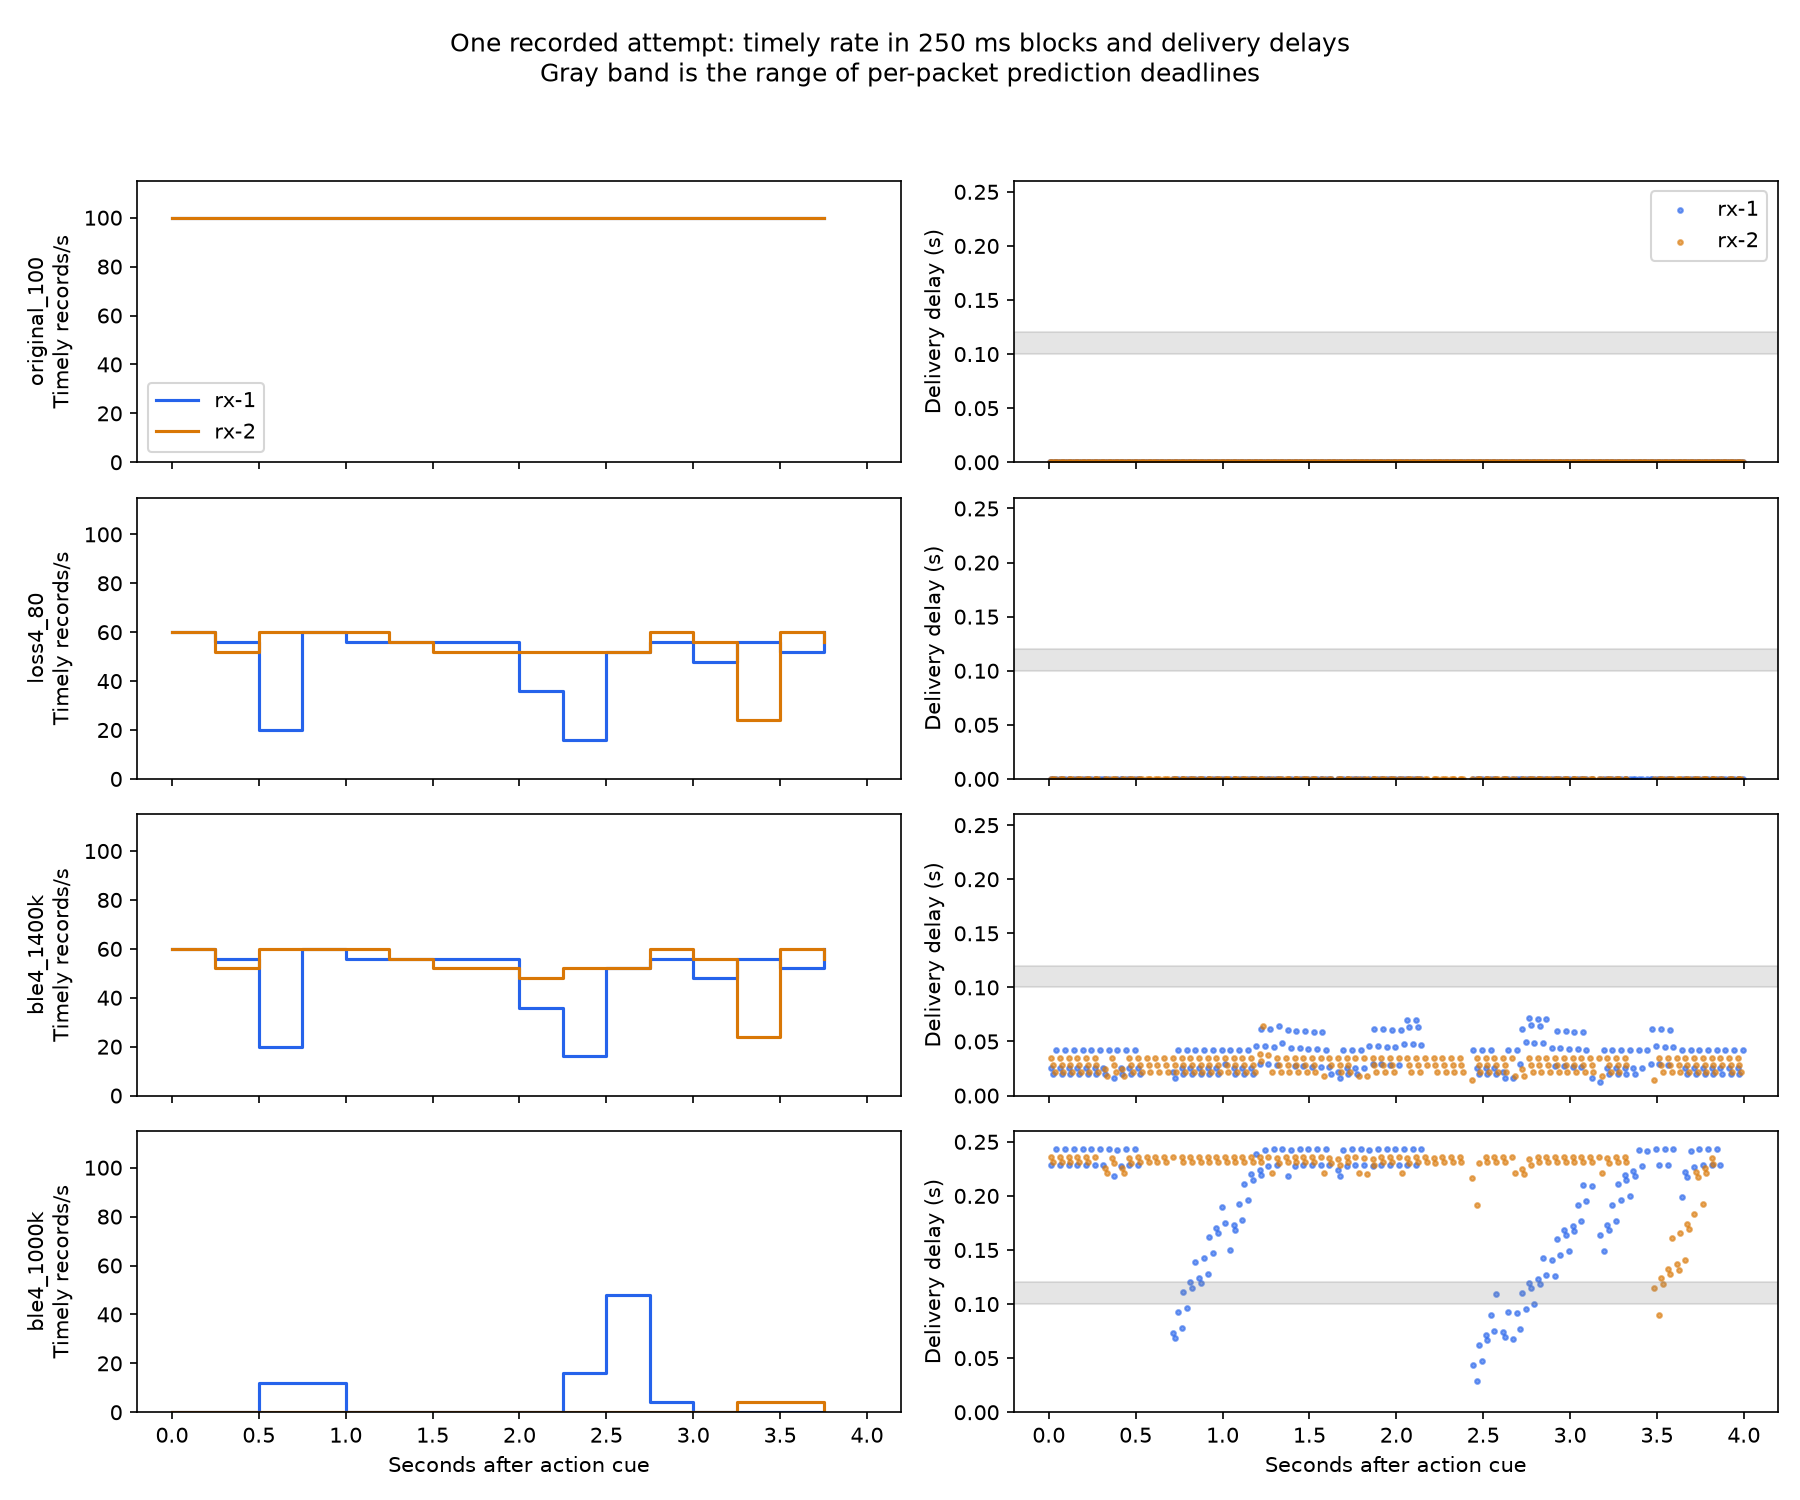

In [4]:
trace = pd.read_csv(RESULTS / "example_packet_trace.csv")
display(trace.groupby(["condition", "receiver", "reason"]).size().unstack(fill_value=0))
display(trace.loc[trace.condition.eq("ble4_1000k")].head(12))
clock = pd.read_csv(RESULTS / "clock_diagnostics.csv")
display(
    clock.groupby("receiver").agg(
        attempts=("attempt_id", "nunique"),
        median_clock_uncertainty_us=("uncertainty_us", "median"),
        maximum_clock_uncertainty_us=("uncertainty_us", "max"),
    )
)
display(Image(filename=str(RESULTS / "figures" / "delivery_timeline.png")))


## 4. Preprocessing and explicit missingness

The pinned HE-LTF decoder retains 242 valid physical tones, masks unusable phase, and removes each packet's magnitude-weighted linear frequency trend. Calibration is packet-local. Capture removal and delivery deadlines are applied before temporal binning.

Four-second action-cue windows use 50 bins/s. Sine/cosine averaging handles circular phase; there is no temporal interpolation or denoising. The CNN receives **12 channels**: four sine/cosine features, four finite-value masks, two delivered-packet counts, and two sample ages. Counts expose a lost packet even when another packet still occupies the same bin. Placeholder values become zero after normalization; masks distinguish them from measurements.

Normalization is fitted only on original training attempts and shared between regimes. Age uses only packets captured before that bin ends and delivered before its deadline. Clock alignment is reconstructed retrospectively from recorded USB synchronization, rather than claiming a tested online synchronizer.

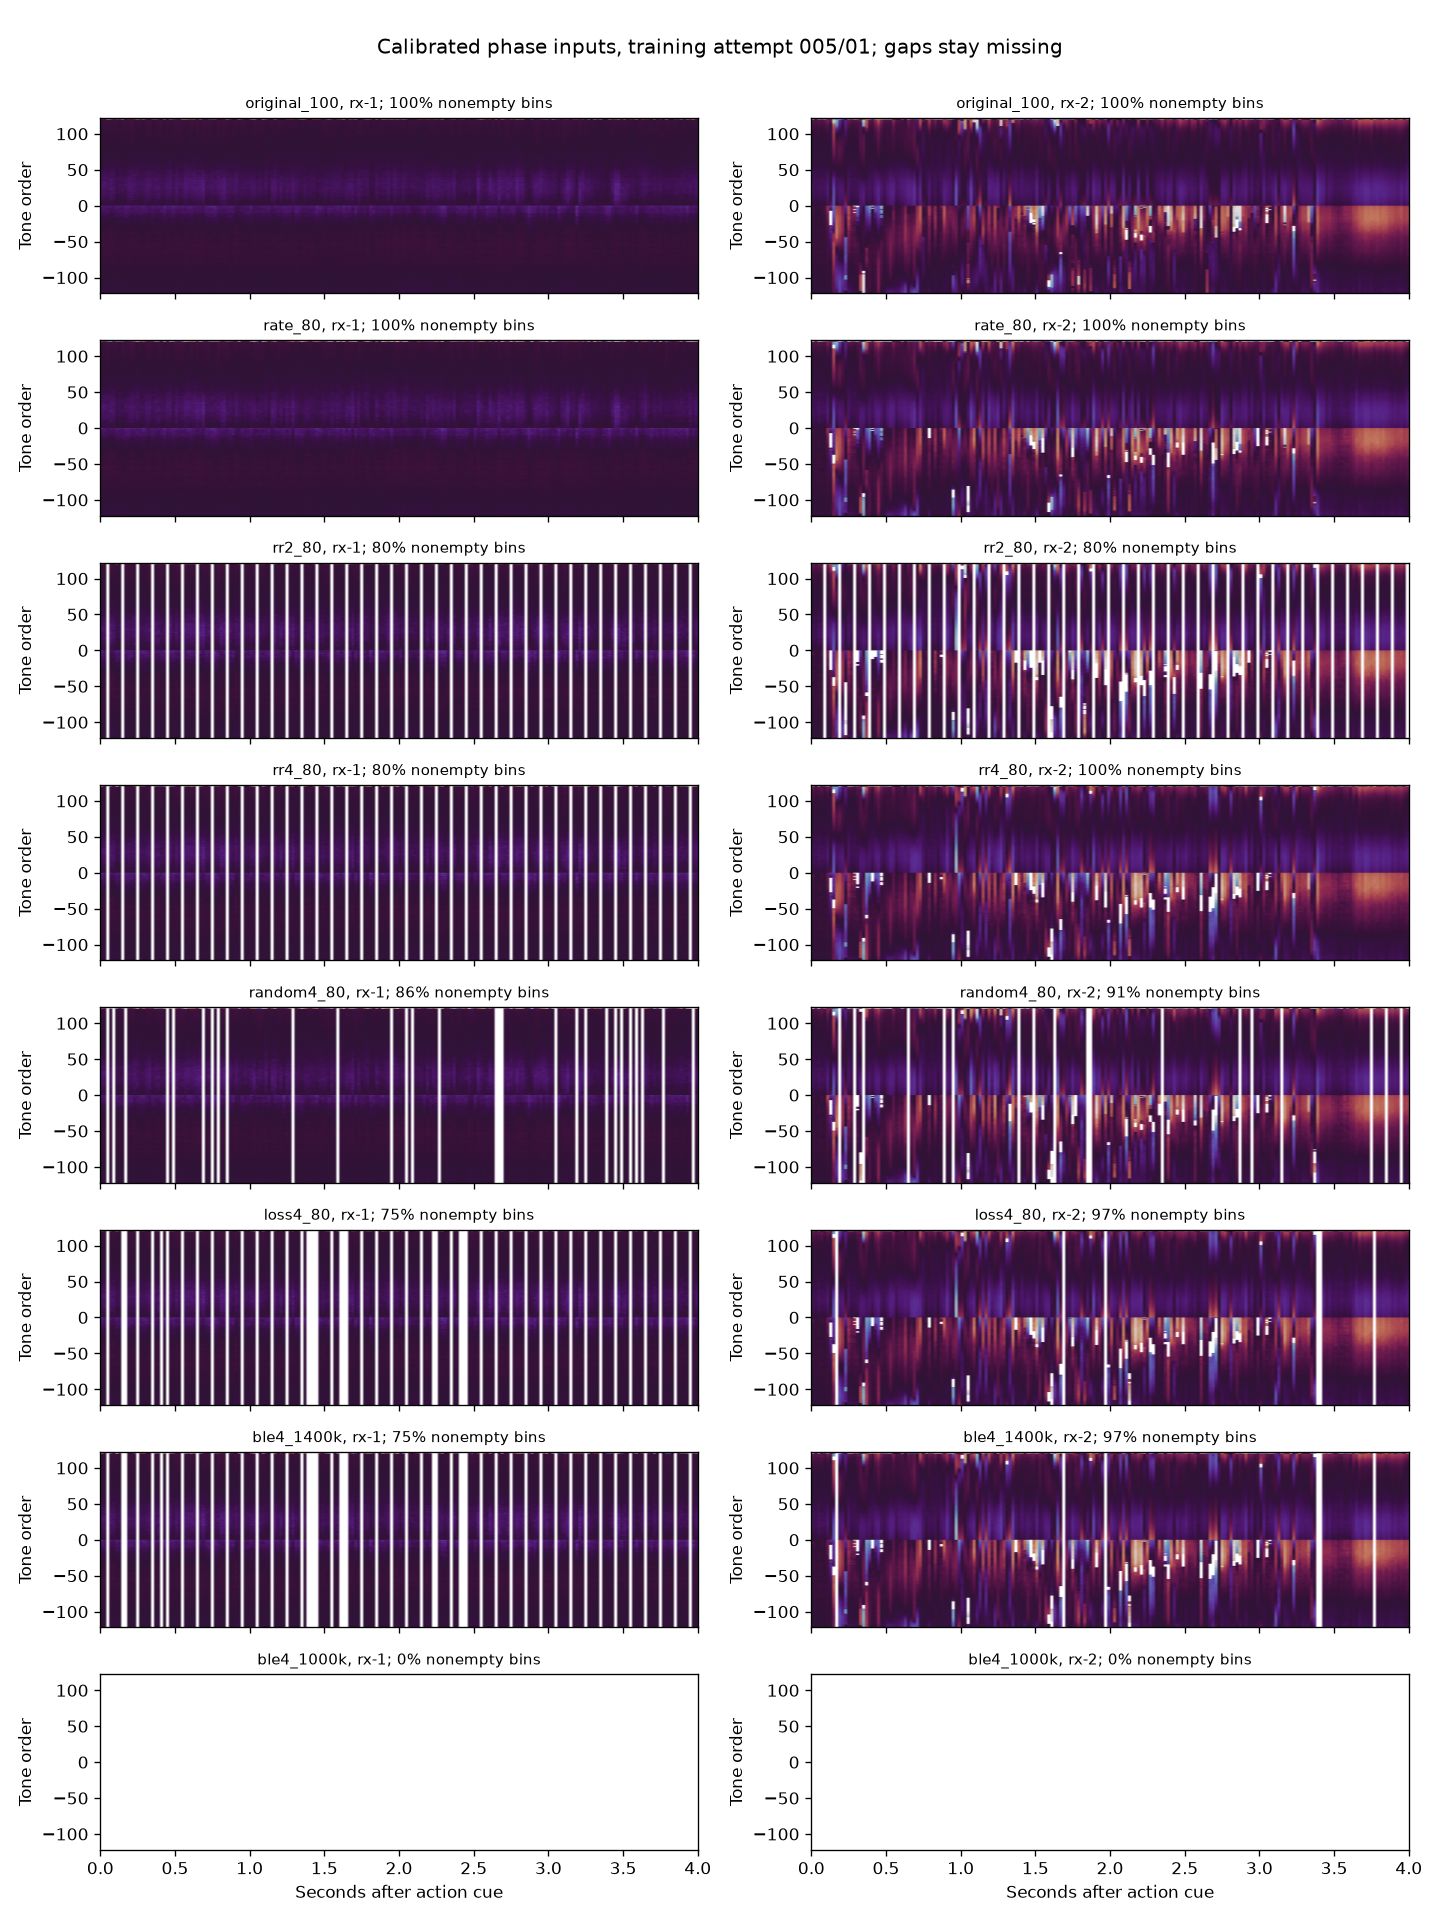

Input window: 4.0 seconds
Bins: 200.0
Delivery grace: 0.1 seconds


In [5]:
display(Image(filename=str(RESULTS / "figures" / "phase_inputs.png")))
print("Input window:", CONFIG["window_seconds"], "seconds")
print("Bins:", CONFIG["bin_hz"] * CONFIG["window_seconds"])
print("Delivery grace:", CONFIG["prediction_grace_seconds"], "seconds")

## 5. Model training

Both regimes use the same small three-layer CNN, weighted binary cross entropy, AdamW, and training seeds 17/29/43. They receive one variant per original training attempt per epoch, so augmentation does not multiply the maximum number of optimizer steps.

The clean regime sees only the source baseline. The missingness-trained regime chooses one prespecified condition and replay seed (101/202) per attempt/epoch. Validation uses seed 303, and test uses the unseen seed 404. Early stopping minimizes source-condition validation BCE for the clean regime and equal-condition validation BCE for the augmented regime. Both regimes are reported, with no test-based selection and a fixed 0.5 threshold.

This classifies a completed four-second cue-aligned attempt plus delivery grace. It is not continuous fall detection or a measured alarm latency.

,regime,seed,best_epoch,validation_loss,validation_conditions
0,clean_trained,17,31,0.195535,[original_100]
1,clean_trained,29,32,0.140928,[original_100]
2,clean_trained,43,34,0.147591,[original_100]
3,missingness_trained,17,30,0.262864,"[original_100, rate_80, rr2_80, rr4_80, random..."
4,missingness_trained,29,32,0.237345,"[original_100, rate_80, rr2_80, rr4_80, random..."
5,missingness_trained,43,18,0.273476,"[original_100, rate_80, rr2_80, rr4_80, random..."


Training time: 221.6 seconds


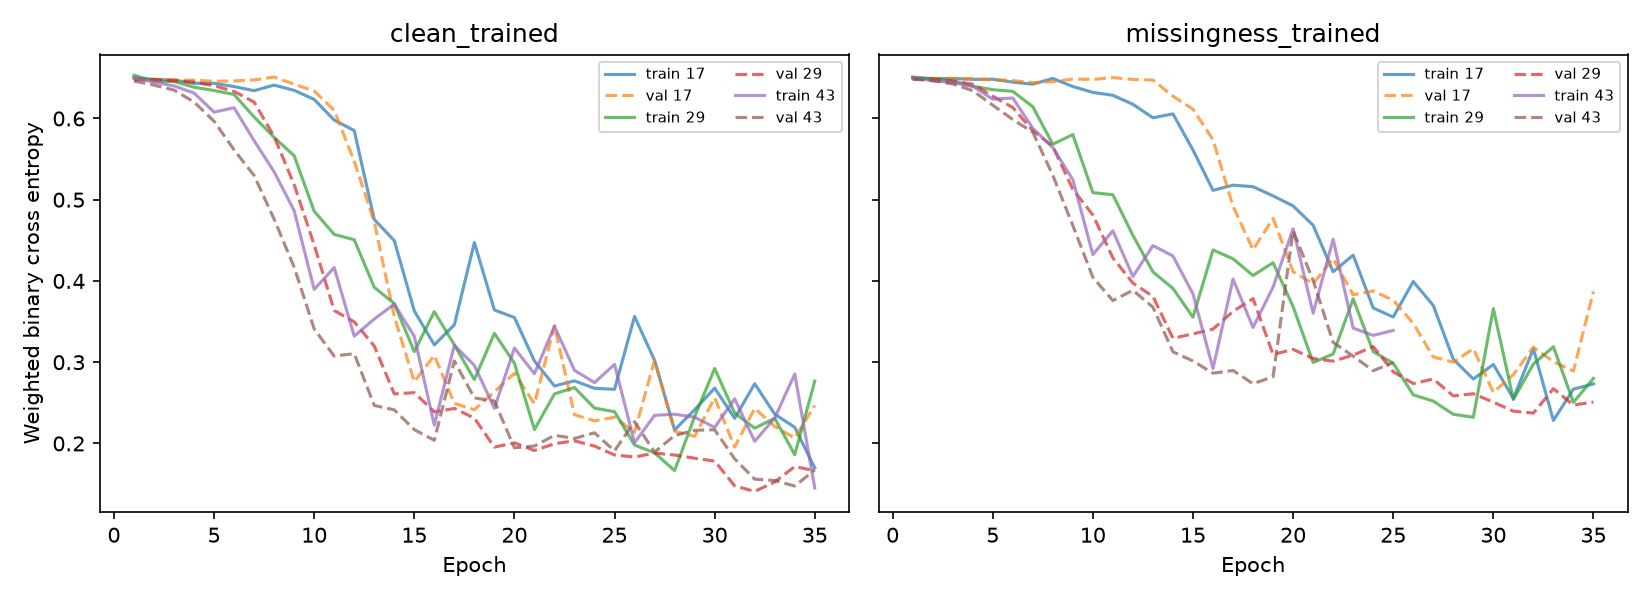

In [6]:
selection = json.loads((RESULTS / "selection.json").read_text())
display(pd.DataFrame(selection["models"]))
print(f"Training time: {selection['training_seconds']:.1f} seconds")
display(Image(filename=str(RESULTS / "figures" / "training_curves.png")))

## 6. Frozen comparison and diagnostic baselines

The same test attempts appear in every condition. Below are the three-seed CNN ensembles, simple signal-summary logistic models, a missingness-only diagnostic, and the majority baseline. The missingness-only model sees quality metadata rather than CSI values. Its performance helps identify acquisition/cohort confounding.

Scenario-cluster bootstrap intervals condition on this one reused split and session. They do not describe uncertainty across people, rooms, or hardware.

## Interpretation of the executed run

Both ensembles classify 28/30 attempts correctly in seven conditions, including
scheduled gaps, random grants, extra burst losses and the 1.4 Mbit/s replay.
Both detect 16/16 falls with 2/14 false-positive non-falls. The clean-trained
model already tolerates these patterns; this run demonstrates no additional
threshold-score benefit from missingness training. Probabilities and ROC AUC
still change, so identical decisions do not establish policy equivalence.

The assumed 1.0 Mbit/s case produces sustained queueing under the configured
fragment cost, grant guard and buffer policy. Many records miss their 100 ms
prediction grace even though they eventually arrive before queue expiry.
Balanced accuracy is 0.500/0.536 for clean/missingness training, with 14/14 and
13/14 false-positive non-falls. This is not evidence that augmentation solves
delivery starvation. It motivates evaluating fresher-first/shorter-expiry
policies and lower offered load in a new, prespecified experiment.

The 0.647 original-condition missingness-only balanced accuracy keeps acquisition
confounding unresolved. All conclusions remain limited to the stated replay
assumptions, two measured views, and the reused within-session scenario split.
No minimum physical adapter throughput or four-view performance was measured.


,regime,condition,balanced_accuracy,fall_recall,specificity,roc_auc,tp,fn,fp,tn
0,clean_trained,original_100,0.929,1.0,0.857,0.987,16,0,2,12
4,clean_trained,rate_80,0.929,1.0,0.857,0.978,16,0,2,12
8,clean_trained,rr2_80,0.929,1.0,0.857,0.982,16,0,2,12
12,clean_trained,rr4_80,0.929,1.0,0.857,0.982,16,0,2,12
16,clean_trained,random4_80,0.929,1.0,0.857,0.982,16,0,2,12
20,clean_trained,loss4_80,0.929,1.0,0.857,0.987,16,0,2,12
24,clean_trained,ble4_1400k,0.929,1.0,0.857,0.987,16,0,2,12
28,clean_trained,ble4_1000k,0.500,1.0,0.000,0.656,16,0,14,0
32,missingness_trained,original_100,0.929,1.0,0.857,0.973,16,0,2,12
36,missingness_trained,rate_80,0.929,1.0,0.857,0.969,16,0,2,12


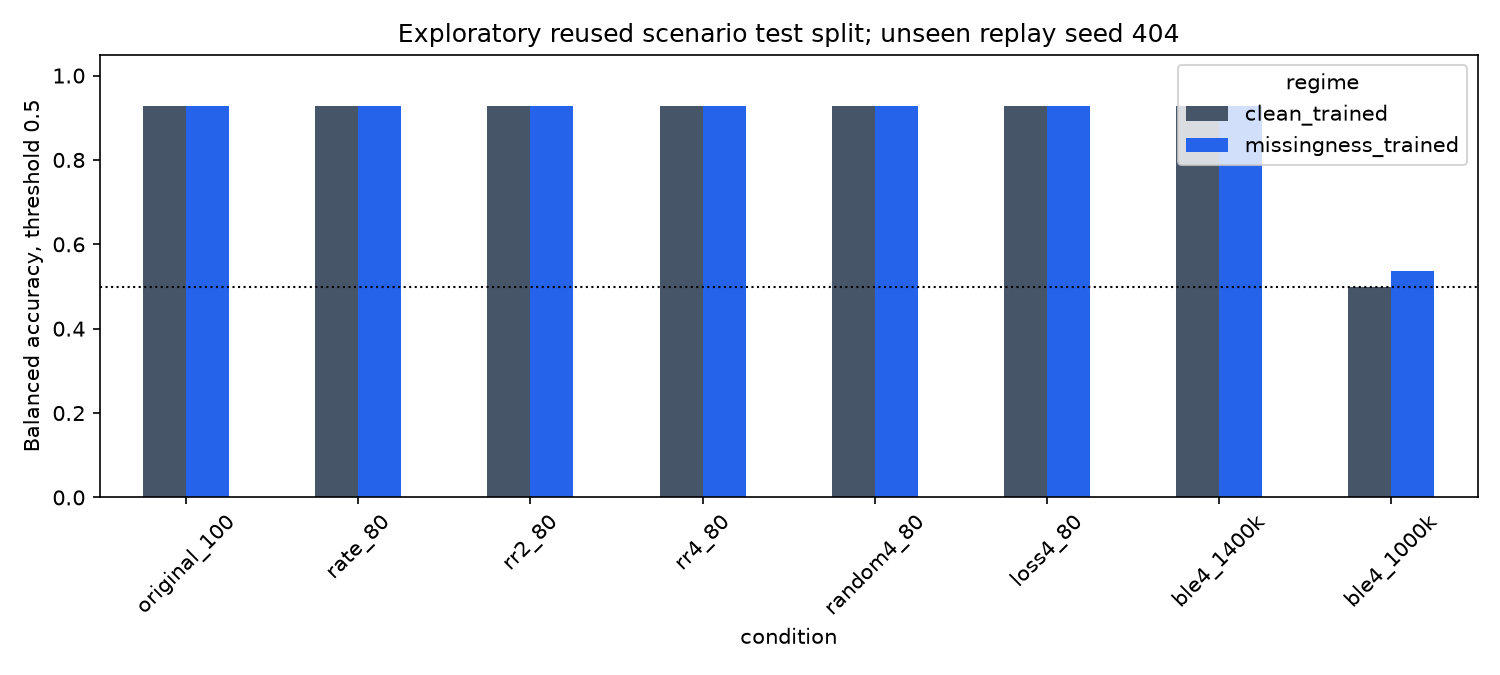

,regime,condition,model,balanced_accuracy,roc_auc
1,clean_trained,original_100,signal_logistic,0.866,0.938
2,clean_trained,original_100,missingness_only,0.647,0.799
3,clean_trained,original_100,majority,0.500,0.500
5,clean_trained,rate_80,signal_logistic,0.500,0.500
6,clean_trained,rate_80,missingness_only,0.500,0.500
7,clean_trained,rate_80,majority,0.500,0.500
9,clean_trained,rr2_80,signal_logistic,0.500,0.500
10,clean_trained,rr2_80,missingness_only,0.500,0.500
11,clean_trained,rr2_80,majority,0.500,0.500
13,clean_trained,rr4_80,signal_logistic,0.500,0.500


In [7]:
metrics = pd.read_csv(RESULTS / "test_metrics.csv")
display(
    metrics.loc[
        metrics.model.eq("cnn"),
        [
            "regime",
            "condition",
            "balanced_accuracy",
            "fall_recall",
            "specificity",
            "roc_auc",
            "tp",
            "fn",
            "fp",
            "tn",
        ],
    ].round(3)
)
display(Image(filename=str(RESULTS / "figures" / "test_comparison.png")))
display(
    metrics.loc[
        metrics.model.ne("cnn"),
        ["regime", "condition", "model", "balanced_accuracy", "roc_auc"],
    ].round(3)
)

In [8]:
intervals = json.loads((RESULTS / "test_intervals.json").read_text())
display(
    pd.DataFrame(
        [
            {
                "regime": row["regime"],
                "condition": row["condition"],
                "BA 95% scenario interval": row["intervals"]["balanced_accuracy"],
                "recall 95% scenario interval": row["intervals"]["fall_recall"],
            }
            for row in intervals
        ]
    )
)
predictions = pd.read_csv(RESULTS / "test_predictions.csv")
errors = predictions.loc[
    predictions.model.eq("cnn") & predictions.prediction.ne(predictions.target)
]
display(errors.head(20))

,regime,condition,BA 95% scenario interval,recall 95% scenario interval
0,clean_trained,original_100,"[0.7669642857142858, 1.0]","[1.0, 1.0]"
1,clean_trained,rate_80,"[0.7669642857142858, 1.0]","[1.0, 1.0]"
2,clean_trained,rr2_80,"[0.7669642857142858, 1.0]","[1.0, 1.0]"
3,clean_trained,rr4_80,"[0.7669642857142858, 1.0]","[1.0, 1.0]"
4,clean_trained,random4_80,"[0.7669642857142858, 1.0]","[1.0, 1.0]"
5,clean_trained,loss4_80,"[0.7669642857142858, 1.0]","[1.0, 1.0]"
6,clean_trained,ble4_1400k,"[0.7669642857142858, 1.0]","[1.0, 1.0]"
7,clean_trained,ble4_1000k,"[0.5, 0.5]","[1.0, 1.0]"
8,missingness_trained,original_100,"[0.7669642857142858, 1.0]","[1.0, 1.0]"
9,missingness_trained,rate_80,"[0.7669642857142858, 1.0]","[1.0, 1.0]"


,attempt_id,scenario_id,label,target,regime,condition,model,probability,prediction
20,115/01,walk-to-sit__start_back__end_left,walk_to_sit,0,clean_trained,original_100,cnn,0.687490,1
21,116/01,walk-to-sit__start_back__end_left,walk_to_sit,0,clean_trained,original_100,cnn,0.598343,1
140,115/01,walk-to-sit__start_back__end_left,walk_to_sit,0,clean_trained,rate_80,cnn,0.758404,1
141,116/01,walk-to-sit__start_back__end_left,walk_to_sit,0,clean_trained,rate_80,cnn,0.628500,1
260,115/01,walk-to-sit__start_back__end_left,walk_to_sit,0,clean_trained,rr2_80,cnn,0.751237,1
261,116/01,walk-to-sit__start_back__end_left,walk_to_sit,0,clean_trained,rr2_80,cnn,0.669283,1
380,115/01,walk-to-sit__start_back__end_left,walk_to_sit,0,clean_trained,rr4_80,cnn,0.796076,1
381,116/01,walk-to-sit__start_back__end_left,walk_to_sit,0,clean_trained,rr4_80,cnn,0.617196,1
500,115/01,walk-to-sit__start_back__end_left,walk_to_sit,0,clean_trained,random4_80,cnn,0.780310,1
501,116/01,walk-to-sit__start_back__end_left,walk_to_sit,0,clean_trained,random4_80,cnn,0.641032,1


## 7. Reproducibility and remaining evidence

The manifest records source hashes, prepared array hashes, configuration, code fingerprints and the frozen split. Selection records checkpoint hashes and dependency versions. Original recordings are never rewritten.

A simulation can measure sensitivity to the chosen losses and service assumptions. It cannot validate four independent CSI views from two recordings, actual BLE scheduling/throughput, true uniform 80 Hz sensing, new-session generalization, or a continuous detector. Those require new measurements. The complete measured report follows.

In [9]:
print("Hashed source files:", len(manifest["source_sha256"]))
print("Hashed prepared arrays:", len(manifest["arrays_sha256"]))
display(Markdown((RESULTS / "REPORT.md").read_text().replace("(figures/", "(results/replay_v1/figures/")))

Hashed source files: 1082
Hashed prepared arrays: 96


# CSI transport replay pilot

Executed on 154 recorded attempts from session `20261026T174653764289Z`,
using two real receivers and the existing frozen pilot scenario split
({'train': 94, 'test': 30, 'validation': 30}). This is a synthetic transport stress
test and cue-aligned attempt classifier. It does not measure BLE hardware or
establish performance on new sessions, participants, or continuous activity.
The reused test partition was already inspected in the previous pilot; these
scores are exploratory and must not become a new tuning target.

## Measured classifier comparison

Three training seeds form each ensemble. Every row uses the same test attempts
and an unseen replay realization (404). Threshold is
fixed at 0.5. Conditions were prespecified, with no post-loss cohort exclusion.

| regime | condition | balanced_accuracy | fall_recall | specificity | roc_auc | tp | fn | fp | tn |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| clean_trained | original_100 | 0.929 | 1.000 | 0.857 | 0.987 | 16 | 0 | 2 | 12 |
| clean_trained | rate_80 | 0.929 | 1.000 | 0.857 | 0.978 | 16 | 0 | 2 | 12 |
| clean_trained | rr2_80 | 0.929 | 1.000 | 0.857 | 0.982 | 16 | 0 | 2 | 12 |
| clean_trained | rr4_80 | 0.929 | 1.000 | 0.857 | 0.982 | 16 | 0 | 2 | 12 |
| clean_trained | random4_80 | 0.929 | 1.000 | 0.857 | 0.982 | 16 | 0 | 2 | 12 |
| clean_trained | loss4_80 | 0.929 | 1.000 | 0.857 | 0.987 | 16 | 0 | 2 | 12 |
| clean_trained | ble4_1400k | 0.929 | 1.000 | 0.857 | 0.987 | 16 | 0 | 2 | 12 |
| clean_trained | ble4_1000k | 0.500 | 1.000 | 0.000 | 0.656 | 16 | 0 | 14 | 0 |
| missingness_trained | original_100 | 0.929 | 1.000 | 0.857 | 0.973 | 16 | 0 | 2 | 12 |
| missingness_trained | rate_80 | 0.929 | 1.000 | 0.857 | 0.969 | 16 | 0 | 2 | 12 |
| missingness_trained | rr2_80 | 0.929 | 1.000 | 0.857 | 0.973 | 16 | 0 | 2 | 12 |
| missingness_trained | rr4_80 | 0.929 | 1.000 | 0.857 | 0.973 | 16 | 0 | 2 | 12 |
| missingness_trained | random4_80 | 0.929 | 1.000 | 0.857 | 0.973 | 16 | 0 | 2 | 12 |
| missingness_trained | loss4_80 | 0.929 | 1.000 | 0.857 | 0.978 | 16 | 0 | 2 | 12 |
| missingness_trained | ble4_1400k | 0.929 | 1.000 | 0.857 | 0.978 | 16 | 0 | 2 | 12 |
| missingness_trained | ble4_1000k | 0.536 | 1.000 | 0.071 | 0.826 | 16 | 0 | 13 | 1 |

Scenario-cluster bootstrap intervals are in `test_intervals.json`; they condition
on this one reused split/session. Seed results and attempt-level probabilities
are included. They do not represent uncertainty across people or hardware.

![Classifier comparison](results/replay_v1/figures/test_comparison.png)

## Interpretation of the executed run

Both ensembles classify 28/30 attempts correctly in seven conditions, including
scheduled gaps, random grants, extra burst losses and the 1.4 Mbit/s replay.
Both detect 16/16 falls with 2/14 false-positive non-falls. The clean-trained
model already tolerates these patterns; this run demonstrates no additional
threshold-score benefit from missingness training. Probabilities and ROC AUC
still change, so identical decisions do not establish policy equivalence.

Replay includes countdown before the action window, so queues are warmed up
rather than artificially reset at the cue. The assumed 1.0 Mbit/s case produces
sustained queueing under the configured
fragment cost, grant guard and buffer policy. Many records miss their 100 ms
prediction grace even though they eventually arrive before queue expiry.
Balanced accuracy is 0.500/0.536 for clean/missingness training, with 14/14 and
13/14 false-positive non-falls. This is not evidence that augmentation solves
delivery starvation. It motivates evaluating fresher-first/shorter-expiry
policies and lower offered load in a new, prespecified experiment.

The 0.647 original-condition missingness-only balanced accuracy keeps acquisition
confounding unresolved. All conclusions remain limited to the stated replay
assumptions, two measured views, and the reused within-session scenario split.
No minimum physical adapter throughput or four-view performance was measured.

## Training-cohort packet EDA

The following measurements use training attempts and realization 101 only.
Timely means delivered by the capture bin's end plus the fixed 100 ms grace.
Longest gaps include unsupported intervals at the edges of the four-second window.

| condition | receiver | attempts | median_timely_hz | p10_timely_hz | p90_longest_gap_s | median_p95_delay_s | median_peak_queue |
| --- | --- | --- | --- | --- | --- | --- | --- |
| ble4_1000k | rx-1 | 94 | 0.000 | 0.000 | 4.000 | 0.239 | 16.000 |
| ble4_1000k | rx-2 | 94 | 0.000 | 0.000 | 4.000 | 0.241 | 16.000 |
| ble4_1400k | rx-1 | 94 | 54.000 | 51.250 | 0.190 | 0.064 | 5.000 |
| ble4_1400k | rx-2 | 94 | 54.000 | 51.500 | 0.180 | 0.062 | 5.000 |
| loss4_80 | rx-1 | 94 | 54.000 | 51.250 | 0.190 | 0.000 | 0.000 |
| loss4_80 | rx-2 | 94 | 54.000 | 51.500 | 0.180 | 0.000 | 0.000 |
| original_100 | rx-1 | 94 | 100.000 | 100.000 | 0.010 | 0.000 | 0.000 |
| original_100 | rx-2 | 94 | 100.000 | 100.000 | 0.010 | 0.000 | 0.000 |
| random4_80 | rx-1 | 94 | 60.250 | 57.750 | 0.077 | 0.000 | 0.000 |
| random4_80 | rx-2 | 94 | 60.000 | 57.750 | 0.080 | 0.000 | 0.000 |
| rate_80 | rx-1 | 94 | 80.000 | 80.000 | 0.020 | 0.000 | 0.000 |
| rate_80 | rx-2 | 94 | 80.000 | 80.000 | 0.020 | 0.000 | 0.000 |
| rr2_80 | rx-1 | 94 | 40.000 | 40.000 | 0.030 | 0.000 | 0.000 |
| rr2_80 | rx-2 | 94 | 40.000 | 40.000 | 0.030 | 0.000 | 0.000 |
| rr4_80 | rx-1 | 94 | 60.000 | 60.000 | 0.030 | 0.000 | 0.000 |
| rr4_80 | rx-2 | 94 | 60.000 | 60.000 | 0.030 | 0.000 | 0.000 |

![Packet coverage](results/replay_v1/figures/packet_coverage.png)
![Joint coverage](results/replay_v1/figures/joint_coverage.png)
![Phase inputs](results/replay_v1/figures/phase_inputs.png)

The next figure uses the first cohort attempt and test replay seed, after model
freezing, to illustrate time-varying availability and queue delay. It is an
example rather than an aggregate result. Deadline bands vary with each
packet's position inside its 20 ms capture bin.

![Delivery timeline](results/replay_v1/figures/delivery_timeline.png)

## Replay assumptions

- `original_100` preserves original packet values, timing and natural losses,
  with ideal replacement transport. `rate_80` retains four of every five source
  rounds, preserving 10/20 ms spacing; it is not a uniform 12.5 ms hardware trace.
- `rr2_80` makes one of the two actual views blind per retained round. Four-slot
  cases make each actual view blind on its assigned turns and add two virtual
  traffic sources. Virtual sources contain byte workloads only, never CSI.
- A grant owner is unavailable for its retained round. A separate uniform
  target-rate clock supplies equal-length grants after a 1 ms sensing guard;
  grants are assumed announced ahead of time. Source capture times retain
  their original thinning jitter. This avoids assigning the repeated 20 ms
  thinning gap to the same receiver on every round-robin cycle.
  Schedule phases/seeds are label-independent. Actual BLE controller events,
  maintenance traffic, ACK latency, RF interference, and stack behavior are
  not reproduced. On-time transfer completion is the application receipt proxy.
- Additional losses: 5% independent loss, a per-round burst-entry probability
  0.015, and burst-exit probability 0.25. These are assumed stresses, not
  estimated ESP32 loss rates. Separate RNG streams keep capture losses paired
  when changing only the transport capacity.
- Constrained cases assume 1.4 or 1.0 Mbit/s shared application service, 32-record
  queues, 250 ms age expiry, oldest-record overflow eviction, 3% whole-transfer
  failure and one retry. A record costs CSI bytes + 119 metadata bytes, plus
  12 assumed header bytes per 232-byte fragment. Partial service carries into
  that receiver's later grants. Unused capacity never accumulates or spills
  into another receiver's grant. Virtual traffic is idealized before injected
  losses; it does not duplicate the original real receivers' natural loss.
- Source losses stay missing. The source sequence grid and USB affine clock
  mapping are reconstructed retrospectively. The replay cannot recover missing
  source observations or emulate changed AGC/phase behavior under real BLE.

## Preprocessing and training

The unchanged pinned HE-LTF decoder performs packet-local phase masking and
weighted linear phase calibration. All 242 usable physical tones remain.
There is no temporal denoising or interpolation. Four-second action-cue windows
use 50 bins/s; circular phases are averaged through sine/cosine only after
simulated capture loss and per-bin delivery deadlines are applied.

The CNN receives four phase channels, four finite-value masks, two packet-count
channels (scaled by two source packets/bin), and two bounded age channels.
Age uses only packets captured before that bin ends and received before its
deadline. A placeholder is zero only after train-only normalization. Those
additional channels expose losses even when a bin still contains one sample.
The prediction uses the complete four-second window plus delivery grace;
this is not a measured fall-alarm latency or streaming detector.

Both regimes use the same original attempts and maximum optimizer steps.
Clean training sees the original condition; missingness training draws one
condition/realization per attempt per epoch. Training replay seeds are 101/202,
validation uses 303, and test uses 404. All variants of a source attempt remain
in its frozen scenario partition. Both regimes share a normalizer fitted only
to original training attempts. Architecture is the pilot's small three-layer
CNN, AdamW, class-weighted BCE and validation early stopping. Clean checkpoints
minimize original-condition validation BCE; augmented checkpoints minimize
equal-condition validation BCE. Both regimes are reported without test-based
selection. Training took 221.6 seconds.

![Training curves](results/replay_v1/figures/training_curves.png)

## Missingness-only diagnostic

This baseline sees availability, packet-count and age summaries, without signal
values. Nonchance performance can reflect acquisition/cohort confounding and
must be considered when interpreting CNN results. Signal-summary logistic and
majority comparisons are also in `test_metrics.csv`.

| regime | condition | balanced_accuracy | roc_auc |
| --- | --- | --- | --- |
| clean_trained | original_100 | 0.647 | 0.799 |
| clean_trained | rate_80 | 0.500 | 0.500 |
| clean_trained | rr2_80 | 0.500 | 0.500 |
| clean_trained | rr4_80 | 0.500 | 0.500 |
| clean_trained | random4_80 | 0.500 | 0.500 |
| clean_trained | loss4_80 | 0.500 | 0.500 |
| clean_trained | ble4_1400k | 0.500 | 0.500 |
| clean_trained | ble4_1000k | 0.500 | 0.500 |
| missingness_trained | original_100 | 0.500 | 0.496 |
| missingness_trained | rate_80 | 0.500 | 0.491 |
| missingness_trained | rr2_80 | 0.500 | 0.464 |
| missingness_trained | rr4_80 | 0.424 | 0.594 |
| missingness_trained | random4_80 | 0.500 | 0.509 |
| missingness_trained | loss4_80 | 0.500 | 0.607 |
| missingness_trained | ble4_1400k | 0.500 | 0.607 |
| missingness_trained | ble4_1000k | 0.438 | 0.371 |

## Reproducibility and limits

`manifest.json` pins 1082 source hashes, all prepared
array hashes, reused decoder/model code, config and split. `selection.json`
pins checkpoints and package versions. Raw data is read-only. Large arrays
and checkpoints stay in ignored `artifacts/`; this folder contains small
reports, plots, diagnostics and predictions. Rerun commands are in the README.

This pilot can assess robustness to the stated missingness/service model for
two measured CSI views. Four-receiver model performance, actual BLE feasibility,
true uniform 80 Hz sampling, independent-session generalization and alarm
latency require new measurements. No simulated throughput is a hardware result.


## Optional full rerun

Leave the switch off to inspect the saved experiment. Enabling it runs preparation, EDA, training, evaluation and reporting into separate directories. Preparation rejects an existing prepared destination; choose new names for repeated runs. Use the pinned pilot environment described in the README.

In [10]:
RERUN = False
if RERUN:
    import subprocess

    subprocess.run(
        [
            sys.executable,
            str(ROOT / "run.py"),
            "--output",
            str(ROOT / "artifacts" / "notebook_rerun"),
            "--results",
            str(ROOT / "results" / "notebook_rerun"),
        ],
        check=True,
    )
else:
    print("Saved results inspected; no simulation or training rerun requested.")

Saved results inspected; no simulation or training rerun requested.
